(i) Simulate 4 × 105 patch visits at T = 2, T∗ and 10 and compare the measured intake with R(T). (ii) Plot R(T) together with the line Rknown and the curve λ˜(T), marking T∗ and R∗.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Part (i) 
# Parameters
pH = 0.5
rho = 0.5
tau = 5
N = 400000
T_star = 4.1814

# Randomize patches & discovery rates
np.random.seed(42)
high_patch = np.random.rand(N) < pH
food_time = np.random.exponential(scale = 1/rho, size = N)

# Simulate
for T in [2, T_star, 10]:
    food = high_patch & (food_time <= T)
    time = np.where(high_patch, np.minimum(food_time, T), T)
    total_time = np.sum(time) + N*tau
    intake_rate = np.sum(food)/total_time
    theoretical_rate = (pH * (1 - np.exp(-rho * T))) / (pH * (1 - np.exp(-rho * T)) / rho + (1 - pH) * T + tau)

    print(f"T = {T:.4f}")
    print(f"Measured intake rate = {intake_rate:.4f}")
    print(f"R(T) = {theoretical_rate:.4f}")
    print()

T = 2.0000
Measured intake rate = 0.0477
R(T) = 0.0477

T = 4.1814
Measured intake rate = 0.0550
R(T) = 0.0550

T = 10.0000
Measured intake rate = 0.0451
R(T) = 0.0452



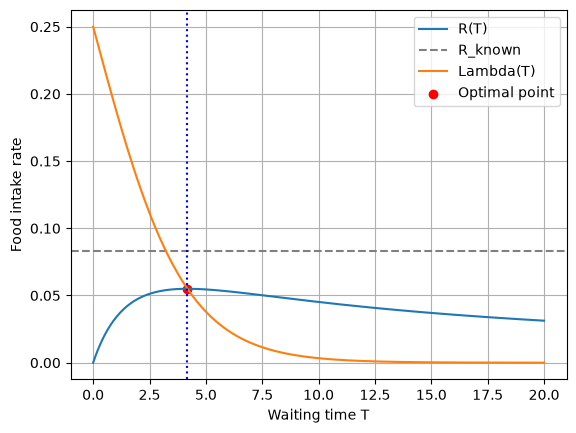

In [6]:
# Part (ii)
# Parameters
pH = 0.5
rho = 0.5
tau = 5
T_star = 4.1814

def R(T):
    return (pH * (1 - np.exp(-rho * T))) / (pH * (1 - np.exp(-rho * T)) / rho + (1 - pH) * T + tau)

def lambda_tilde(T):
    return (rho * pH * np.exp(-rho * T)) / (pH * np.exp(-rho * T) + 1 - pH)

R_star = R(T_star)
R_known = pH / (pH / rho + tau)

# Make plots
T = np.linspace(0, 20, 400)

plt.plot(T, R(T), label = "R(T)")
plt.axhline(R_known, linestyle = "--", color = "gray", label = "R_known")
plt.plot(T, lambda_tilde(T), label = "Lambda(T)")
plt.scatter(T_star, R_star, color = "red", label = "Optimal point")
plt.axvline(T_star, linestyle = ":", color = "blue")

plt.xlabel("Waiting time T")
plt.ylabel("Food intake rate")
plt.legend()
plt.grid()
plt.show()
